# Headless MRiLab spectrum generation

Generate simulated spectra and ground truth at explicit `(x, y, z)` voxel-center indices. This notebook does not open the GUI. Convert results to plot-ready NIfTI-MRS objects, and optionally save them with ground-truth sidecars.

In [1]:
from pathlib import Path
import os

project_root = Path.cwd()
if not (project_root / 'data/skeletons/MRiLab').is_dir():
    project_root = project_root.parent
os.chdir(project_root)

from simulation.headless import results_to_nifti_mrs, simulate_batch

/Users/wclarke/Documents/Python/MRS-Digital-Phantom/.pixi/envs/default/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Configure the legacy MRiLab example using the checked-in Philips PRESS TE30 basis. The anatomical dataset and legacy lipid simulation dependencies are still required.

Existing legacy outputs below are historical and were preserved; they have not been rerun with this portable basis default. The quantitative demonstration is now in `quantitative_headless_simulation.ipynb`; that notebook has been executed independently.


In [ ]:
settings = {
    'path2basis': 'data/basissets/LCModel_Universal_Philips_UnEdited_PRESS_TE30.BASIS',
    'basis_set_settings': {
        'vendor': 'Philips',
        'localization': 'PRESS',
        'TE': 30,
    },
    'voxel_size_mm': (10.0, 10.0, 10.0),
    'simulation_params': {
        'spectral_points': 2048,
        'TR': 2000.0,
        'bandwidth': 2000.0,
        'noise_level': 1.0,
        'mm_level': 25.0,
        'mm_json_file': './data/macromolecules/mm_params.json',
        'lipid_amp_factor': 40.0,
        'lipid_sigma': 5.0,
        'lipid_phase_min': -180.0,
        'lipid_phase_max': 180.0,
        'lipid_lw_min': 30.0,
        'lipid_lw_max': 50.0,
        'water_amp_factor': 5.0,
        'water_phase_min': -180.0,
        'water_phase_max': 180.0,
        'water_damping_min': 0.0,
        'water_damping_max': 50.0,
        'shim_amplitude_hz': 3.0,
        'shim_corr_length': 1.0,
        'shim_boundary_amp_factor': 1.5,
        'shim_boundary_smoothing': 2.0,
    },
}

# Replace these with valid zero-based (x, y, z) indices in the MRiLab array.
positions = [(100, 108, 80), (100, 108, 80) ,(110, 108, 80)]
seed = 1234 # Set to `None` for no seed - different each execution. Each position will have a different draw even if defined seed.
nifti_output_dir = None  # For example: './outputs/headless_batch'
total_components = None  # None means all components when saving
individual_components = []

## Generate

Simulation returns spectra and ground truth in memory. Convert them to NIfTI-MRS objects for plotting; set `nifti_output_dir` to also save NIfTI files and sidecars.

In [43]:
results = simulate_batch(
    positions=positions,
    settings=settings,
    seed=seed,
)

for res in results:
    print(res['ground_truth']['tissue_fractions'])


Metabolites to ignore from basisset: [np.str_('EA'), np.str_('CrCH2'), np.str_('bHG'), np.str_('Ser'), np.str_('Ala'), np.str_('Cystat')]
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/7ab4eec1c3d73b7c902cad3c674ee819.mat
{'Background': 0.0, 'WM': 0.1940000057220459, 'GM': 0.8060000538825989, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}
{'Background': 0.0, 'WM': 0.1940000057220459, 'GM': 0.8060000538825989, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}
{'Background': 0.0, 'WM': 0.9770000576972961, 'GM': 0.023000001907348633, 'CSF': 0.0, 'Fat': 0.0, 'Skull': 0.0}


## Convert, plot, and optionally save

The converter returns a total `NIFTI_MRS` object and selected component objects for each voxel. With no output directory, nothing is written; with one set, the objects and sidecars are saved and remain available here.

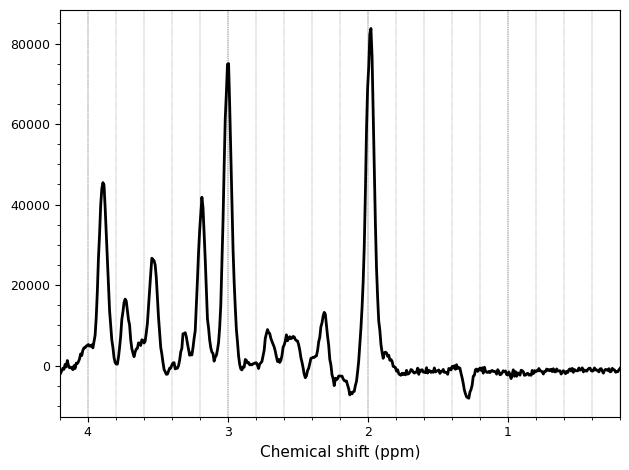

In [45]:
nifti_results = results_to_nifti_mrs(
    results,
    output_dir=nifti_output_dir,
    total_components=total_components,
    individual_components=individual_components,
)

_ = nifti_results[1]['total'].plot()

## Batch simulation with a separate BASIS-H2O reference

This opt-in example retains the old concentration table, shim controls, residual water, macromolecules, lipids and batch seed. Table values are explicitly **assumed nominal mM**; no IU conversion is inferred. The reference uses the same full-BASIS normalization, actual shim map and volume sum as metabolites. It is separate from residual contamination. Legacy lipid simulation dependencies/cache are required.


In [6]:
from pathlib import Path
from datetime import datetime, timezone
import os
import sys

# This section also runs independently in a fresh kernel started in notebooks/.
repository_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'simulation/headless.py').is_file()), None)
if repository_root is None:
    raise RuntimeError('Start the notebook within the MRS-Digital-Phantom checkout')
os.chdir(repository_root)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

import numpy as np
from fsl_mrs.utils import mrs_io
from examples.legacy_basis_water import configuration
from simulation.headless import simulate_batch, results_to_nifti_mrs
import matplotlib.pyplot as plt

Metabolites to ignore from basisset: [np.str_('Cystat'), np.str_('Ala'), np.str_('bHG'), np.str_('CrCH2'), np.str_('EA'), np.str_('Ser')]
Loading lipid basis set from cache: ./simulation/lipids/lipids_cache/18cdc11b4f53cf345afad2765d19979e.mat
Saved spectrum to outputs/legacy_basis_water_notebook/20261101T182122316149Z/voxel_0000_100_108_80
Output: outputs/legacy_basis_water_notebook/20261101T182122316149Z/voxel_0000_100_108_80
Water provenance: {'basis_sha256': 'f0a42cf0bef1b5427d4f3f3f4e5dd35dd4406581230a7ead1055bd7fbd700a79', 'bandwidth_hz': 2000.0, 'points': 2048, 'frequency_origin_ppm': 4.68, 'water_component_name': 'H2O', 'reference_names': ['Ala', 'Asc', 'Asp', 'Cr', 'CrCH2', 'Cystat', 'EA', 'GABA', 'GPC', 'GSH', 'Gln', 'Glu', 'Gly', 'H2O', 'Lac', 'NAA', 'NAAG', 'PCh', 'PCr', 'PE', 'Ser', 'Tau', 'bHG', 'mI', 'sI'], 'normalization': {'scalar': 6.988104256988194e-05, 'statistic': 'mean_absolute_full_formatted_basis', 'reference_names': ['Ala', 'Asc', 'Asp', 'Cr', 'CrCH2', 'Cystat'

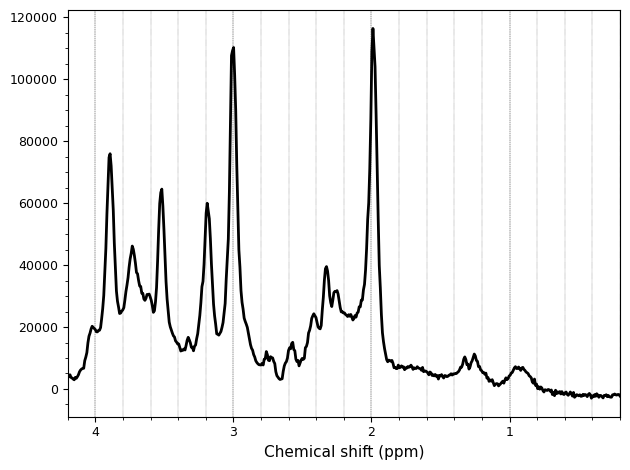

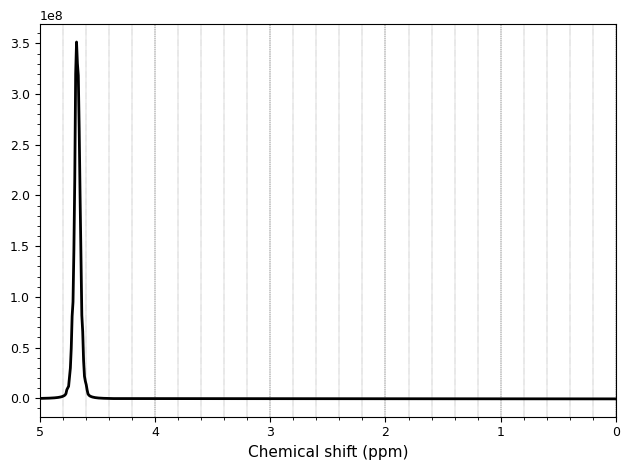

In [ ]:
original_wref_settings = configuration('/Users/wclarke/Downloads/LCM_basis/GE_PRESS_TE35.BASIS')
original_wref_settings['simulation_params']['shim_amplitude_hz'] = 3.0
original_wref_output = Path('outputs/legacy_basis_water_notebook') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
original_wref_result = simulate_batch(
    [(100,108,80),],
    original_wref_settings,
    individual_components=["Metabs",], #  "MMs", "Lipids", "Water", "Noise"
    save_dir=original_wref_output,
    seed=123)

print('Output:', original_wref_result[0]['saved_path'])
print('Water provenance:', original_wref_result[0]['water_reference_provenance'])


original_wref_objects = results_to_nifti_mrs(original_wref_result)[0]

_ = original_wref_objects['total'].plot()
plt.show()

_ = original_wref_objects['water_reference'].plot(ppmlim=(0, 5))
plt.show()
